# 07 · Contraste de las hipótesis

**El trabajo se centra en el modelo C3**, la versión elegida con el protocolo (notebooks 03 a 06). Este notebook contrasta las tres hipótesis con la misma población, el mismo evento (los pagos anticipados cuentan como buenos pagadores) y la misma partición: ajuste con 2023-2024 y prueba con 2025. Las reglas están descritas en la metodología del documento. **C3 y su decisión no cambian.**

| Sección | Papel | Pregunta |
|---|---|---|
| 1 · H1 | **Referencia** | ¿El bloque sociodemográfico-comercial añade capacidad predictiva al financiero-contractual? Se usan modelos de bloques que no compiten con C3 (`src/07a_hipotesis1_bloques.py`). |
| 2 · H2 | **Sobre C3** | ¿Reordenar con el puntaje de C3 dentro de la población aprobada permite aprobar más con el deterioro controlado? (`src/07b_hipotesis2_3.py`) |
| 3 · H3 | **Sobre C3** | ¿Las métricas de C3 difieren entre sexos y estratos? (`src/07b_hipotesis2_3.py`) |
| 4 · Calibración | **Sobre C3** | Calibración en el conjunto. |

In [1]:
import sys, json, importlib.util, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
import protocolo as P
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.float_format", "{:,.4f}".format)
H = RAIZ / "resultados" / "hipotesis"
leer = lambda r: pd.read_csv(r, encoding="utf-8-sig")
def script(nombre):
    spec = importlib.util.spec_from_file_location(nombre.replace(".py", "").lstrip("0123456789_"), RAIZ / "src" / nombre)
    m = importlib.util.module_from_spec(spec); spec.loader.exec_module(m); return m
decision = json.loads(P.DECISION.read_text(encoding="utf-8"))
assert decision["version"] == "C3_V2p", "la versión elegida cambió"
print("Versión elegida (sin cambios):", decision["version"], "|", ", ".join(decision["variables"]))

Versión elegida (sin cambios): C3_V2p | edad, estado_civil, ciudad, independiente_informal, nivel_estudio, familia_moto


## 1. Primera hipótesis: bloques de información (análisis de referencia)

> *El modelo que combina las variables sociodemográficas y comerciales capturadas en la solicitud con la información financiero-contractual presenta un desempeño predictivo fuera de muestra superior al del modelo construido únicamente con información financiero-contractual, medido por la diferencia de ROC-AUC y de Brier sobre una cohorte temporal de prueba.*

Los tres bloques usan el mismo procedimiento de las versiones candidatas: siete algoritmos con Optuna, ensamble, validación cruzada 5×5 dentro de 2023-2024 y calificación de 2025. El contraste principal es E3 − E1 en 2025, con Holm sobre AUC y Brier. **C3 no compite aquí:** E1 y E3 usan condiciones del crédito que se fijan al aprobar, mientras que C3 se puede aplicar antes.

In [2]:
h1 = script("07a_hipotesis1_bloques.py")
pd.DataFrame([{"bloque": b, "n.º de variables": len(v), "variables": ", ".join(v)} for b, v in h1.BLOQUES.items()])

,bloque,n.º de variables,variables
0,E1_financiero,11,"capital, cuota, cuota_inicial, cuota_inicial_pct, tasa, plazo, prenda, precio_moto, propietario_moto_cliente, famili..."
1,E2_sociodemografico,12,"edad, estado_civil, estrato, personas_a_cargo, nivel_estudio, independiente_informal, ciudad, zona_homologada, depar..."
2,E3_combinado,23,"capital, cuota, cuota_inicial, cuota_inicial_pct, tasa, plazo, prenda, precio_moto, propietario_moto_cliente, famili..."


### 1.1 Validación cruzada 2023-2024 (apoyo)

In [3]:
display(leer(H / "h1" / "cv_bloques.csv"))
display(leer(H / "h1" / "cv_diferencias.csv"))

,bloque,n_variables,auc_intra_cosecha,de_pliegues,brier
0,E1_financiero,11,0.6967,0.0234,0.1581
1,E2_sociodemografico,12,0.6105,0.0331,0.1730
2,E3_combinado,23,0.6977,0.0247,0.1572


,comparacion,metrica,diferencia,ic_inf,ic_sup,p,pliegues_a_favor_de_a
0,E3_combinado - E1_financiero,auc,0.0010,-0.0142,0.0162,0.8911,13
1,E3_combinado - E1_financiero,brier,-0.0009,-0.0029,0.0011,0.3468,18
2,E2_sociodemografico - E1_financiero,auc,-0.0861,-0.1326,-0.0397,0.0008,0
3,E2_sociodemografico - E1_financiero,brier,0.0149,0.0101,0.0197,0.0000,0
4,E3_combinado - E2_sociodemografico,auc,0.0872,0.0504,0.1239,0.0001,25
5,E3_combinado - E2_sociodemografico,brier,-0.0158,-0.0199,-0.0117,0.0000,25


### 1.2 Prueba 2025 (contraste principal)

In [4]:
display(leer(H / "h1" / "prueba_2025_bloques.csv"))
d = leer(H / "h1" / "prueba_2025_diferencias.csv")
display(d[["comparacion", "dif_auc", "auc_ic_delong_inf", "auc_ic_delong_sup", "auc_ic_boot_inf", "auc_ic_boot_sup", "p_auc", "p_holm_auc"]])
display(d[["comparacion", "dif_brier", "brier_ic_inf", "brier_ic_sup", "p_brier", "p_holm_brier",
           "dif_brier_T2_recalibrado", "brier_T2_ic_inf", "brier_T2_ic_sup"]])

,bloque,n,eventos,auc,auc_ic_inf,auc_ic_sup,prob_media,brier,brier_constante,brier_T2_sin_recalibrar,brier_T2_recalibrado_T1
0,E1_financiero,1033,93,0.6748,0.6180,0.7317,0.1404,0.0803,0.0819,0.0731,0.0685
1,E2_sociodemografico,1033,93,0.5908,0.5266,0.6551,0.2180,0.0983,0.0819,0.0919,0.0713
2,E3_combinado,1033,93,0.6880,0.6318,0.7442,0.1507,0.0800,0.0819,0.0744,0.0682
3,segmento,1033,93,0.5262,0.4922,0.5601,NaN,NaN,NaN,NaN,NaN


,comparacion,dif_auc,auc_ic_delong_inf,auc_ic_delong_sup,auc_ic_boot_inf,auc_ic_boot_sup,p_auc,p_holm_auc
0,E3_combinado - E1_financiero,0.0131,-0.0140,0.0403,-0.0127,0.0418,0.3425,0.6849
1,E2_sociodemografico - E1_financiero,-0.0840,-0.1576,-0.0104,-0.1540,-0.0088,0.0254,NaN
2,E3_combinado - E2_sociodemografico,0.0971,0.0422,0.1521,0.0428,0.1518,0.0005,NaN


,comparacion,dif_brier,brier_ic_inf,brier_ic_sup,p_brier,p_holm_brier,dif_brier_T2_recalibrado,brier_T2_ic_inf,brier_T2_ic_sup
0,E3_combinado - E1_financiero,-0.0003,-0.0018,0.0012,0.6990,0.6990,-0.0003,-0.0016,0.0011
1,E2_sociodemografico - E1_financiero,0.0179,0.0134,0.0224,0.0000,NaN,0.0028,-0.0019,0.0078
2,E3_combinado - E2_sociodemografico,-0.0183,-0.0219,-0.0145,0.0000,NaN,-0.0031,-0.0078,0.0013


### 1.3 Otros objetivos con el mismo puntaje (descriptivo)

In [5]:
leer(H / "h1" / "prueba_2025_otros_objetivos.csv").pivot_table(index="bloque", columns="objetivo", values="auc")

objetivo,mora30_3m,mora60_6m,mora90_6m
bloque,,,
E1_financiero,0.7627,0.6924,0.7687
E2_sociodemografico,0.6089,0.5987,0.5966
E3_combinado,0.7728,0.7049,0.7670
segmento,0.5466,0.5240,0.5312


### 1.4 Referencia: C3 frente a los bloques en 2025 (exploratorio)

In [6]:
import utilidades_auc as U
b = pd.read_parquet(H / "h1" / "puntajes_2025_bloques.parquet")
s = pd.read_parquet(P.SALIDA / "reporte_2025" / "puntajes_2025.parquet")[["id_obligacion", "score__C3_V2p"]]
t = b.merge(s, on="id_obligacion")
t = t[t[P.Y].notna()]
y = t[P.Y].astype(int).values
filas = []
for o in ["E1_financiero", "E2_sociodemografico", "E3_combinado", "segmento"]:
    a1, a2, d, ee, i1, i2, p = U.delong(y, t["score__C3_V2p"].values, t[f"score__{o}"].values)
    filas.append({"frente_a": o, "AUC C3": a1, "AUC del otro": a2, "diferencia": d, "IC inf": i1, "IC sup": i2, "p": p})
pd.DataFrame(filas)

,frente_a,AUC C3,AUC del otro,diferencia,IC inf,IC sup,p
0,E1_financiero,0.6197,0.6748,-0.0552,-0.1173,0.0070,0.0821
1,E2_sociodemografico,0.6197,0.5908,0.0288,-0.0213,0.0790,0.2597
2,E3_combinado,0.6197,0.6880,-0.0683,-0.1174,-0.0192,0.0064
3,segmento,0.6197,0.5262,0.0935,0.0197,0.1673,0.0130


**Lectura de H1 (análisis de referencia):**
- **En 2025, el bloque combinado (E3) no supera al financiero-contractual (E1):**
  - AUC de 0,688 [0,632; 0,744] frente a 0,675 [0,618; 0,732].
  - Diferencia E3 − E1: +0,013 [−0,014; +0,040] (DeLong), con p de Holm de 0,68.
  - En Brier, la diferencia es −0,0003 [−0,0018; +0,0012], con p de Holm de 0,70. Recalibrando el intercepto con 2025-T1 queda en −0,0003 [−0,0016; +0,0011].
  - **H1 no se sostiene ni en discriminación ni en calibración.**
- **La validación cruzada 2023-2024 apunta en la misma dirección:** E3 − E1 = +0,001 [−0,014; +0,016] en AUC dentro de cosecha y −0,0009 [−0,0029; +0,0011] en Brier, con 13 y 18 de los 25 pliegues a favor de E3.
- **Lo contrario sí se sostiene.** Añadir el bloque financiero-contractual al sociodemográfico-comercial mejora el AUC en +0,097 [+0,042; +0,152] en 2025 (p < 0,001) y en +0,087 [+0,050; +0,124] en validación cruzada; el Brier baja 0,018. La capacidad predictiva se concentra en las condiciones del crédito y del producto.
- **El bloque financiero-contractual sigue mejor el nivel del riesgo en 2025:** predice en promedio 14,0 % frente a 9,0 % observado, y su Brier (0,080) queda por debajo del de una constante (0,082). Es coherente con que sus variables recogen los cambios de política entre cosechas (notebook 06). Parte de la ventaja de E1 en 2025 puede venir de la prenda, exigida desde el 18 de febrero de 2025, dentro de la propia cohorte de prueba.
- **Por qué esto no cambia el modelo del trabajo:**
  - E1 y E3 usan la tasa, el plazo, la cuota inicial y la prenda, que se fijan al aprobar. C3 se puede aplicar antes de fijar esas condiciones.
  - En 2025, E3, que contiene a C3, la supera en +0,068 [+0,019; +0,117] (p = 0,006). Como referencia, es una cota superior del aporte de las condiciones del crédito, porque E3 agrega otras diez variables además de ellas. La diferencia con E1 (C3 queda en −0,055 [−0,117; +0,007]; p = 0,082) no mide ese aporte, porque C3 y E1 difieren en más que las condiciones.
  - Todos los bloques quedan por encima del segmento vigente (0,526).

### 1.5 Sensibilidad: E1 solo con las condiciones del crédito (exploratorio)

E1 sigue la tabla del escenario financiero-contractual de la propuesta: además de las condiciones del crédito incluye variables del producto (precio, moto a nombre del cliente, familia de moto y cilindraje), y la familia de moto es la variable más importante de C3 (notebook 08). Como sensibilidad, **fuera del contraste registrado**, se ajusta con el mismo procedimiento —Optuna, validación cruzada 5×5 dentro de 2023-2024 y una sola calificación de 2025— un bloque solo con las siete condiciones del crédito: capital, cuota, cuota inicial en pesos y en porcentaje, tasa, plazo y prenda (`src/07a_hipotesis1_bloques.py`, pasos `cv E1_condiciones` y `sensibilidad`). Se compara con E3 y con E1 en los mismos pliegues y, en 2025, con sus puntajes guardados; reajustar E1 con sus parámetros reproduce esos puntajes (diferencia máxima de 1,1 × 10⁻¹⁶).

In [7]:
display(leer(H / "h1" / "sensibilidad_E1_condiciones_bloques.csv"))
display(leer(H / "h1" / "sensibilidad_E1_condiciones_diferencias.csv"))

,bloque,n_variables,auc_cv,brier_cv,n_2025,eventos_2025,auc_2025,auc_ic_inf,auc_ic_sup,prob_media_2025,brier_2025
0,E1_condiciones,7,0.6920,0.1594,1033,93,0.6804,0.6243,0.7365,0.1448,0.0811
1,E1_financiero,11,0.6967,0.1581,1033,93,0.6748,0.6180,0.7317,0.1404,0.0803
2,E3_combinado,23,0.6977,0.1572,1033,93,0.6880,0.6318,0.7442,0.1507,0.0800


,comparacion,dif_auc_cv,auc_cv_ic_inf,auc_cv_ic_sup,p_auc_cv,pliegues_a_favor_de_a,dif_brier_cv,brier_cv_ic_inf,brier_cv_ic_sup,p_brier_cv,dif_auc_2025,auc_ic_delong_inf,auc_ic_delong_sup,auc_ic_boot_inf,auc_ic_boot_sup,p_auc_2025,dif_brier_2025,brier_ic_inf,brier_ic_sup,p_brier_2025
0,E3_combinado - E1_condiciones,0.0057,-0.0101,0.0214,0.4652,15,-0.0022,-0.0043,-0.0001,0.0422,0.0076,-0.0224,0.0375,-0.0217,0.0370,0.6207,-0.0011,-0.0028,0.0005,0.1880
1,E1_financiero - E1_condiciones,0.0046,-0.0055,0.0148,0.3562,21,-0.0013,-0.0028,0.0002,0.0903,-0.0056,-0.0227,0.0115,-0.0230,0.0113,0.5219,-0.0008,-0.0018,0.0002,0.1140


**Lectura de la sensibilidad:**
- **Sin las variables del producto, el bloque ordena igual:** AUC de 0,680 [0,624; 0,736] en 2025, frente a 0,675 de E1, y 0,692 frente a 0,697 en validación cruzada. La diferencia E1 − E1 solo con condiciones es de −0,006 [−0,023; +0,012] en 2025 (p = 0,522): la capacidad predictiva del bloque está en las condiciones del crédito.
- **E3 tampoco supera al bloque solo con condiciones en 2025:** +0,008 [−0,022; +0,038] en AUC (DeLong, p = 0,621) y −0,0011 [−0,0028; +0,0005] en Brier (p = 0,188).
- **En validación cruzada:** +0,006 [−0,010; +0,021] en AUC (p = 0,465; 15 de 25 pliegues a favor de E3) y −0,0022 [−0,0043; −0,0001] en Brier (p = 0,042, sin corrección por multiplicidad).
- **Con el criterio registrado (2025), la conclusión de H1 se mantiene sin las variables del producto en E1.**

## 2. Segunda hipótesis: reordenación dentro de la población aprobada

> *Dentro de la población históricamente aprobada es posible identificar umbrales de clasificación que aumenten la proporción de clientes considerados elegibles por el modelo, manteniendo controlado el deterioro esperado.*

Toda la base corresponde a créditos aprobados, así que la hipótesis se contrasta como **reordenación**, con el puntaje de C3 en la prueba 2025 y frente al segmento vigente:
- **(a) A igual tasa de aprobación:** cuánto deterioro queda entre los aprobados.
- **(b) A igual deterioro:** qué fracción se puede aprobar.

Puntos principales: aprobar el 80 % en (a) y deterioro de 9 % como máximo en (b). La regla registrada se lee en (b). Como la mora de la prueba es de 9,0 %, se agrega como análisis complementario un máximo de 7 % y se reporta también el de 8 %. Como el segmento solo tiene tres categorías, dentro de cada una el orden se asigna al azar (en valor esperado). Ampliar la cobertura a solicitantes rechazados exigiría inferencia de rechazados y queda fuera del alcance.

In [8]:
r = leer(H / "h2" / "reordenacion.csv")
display(r.drop(columns="poblacion"))

,analisis,punto,metrica,modelo,segmento,cartera_completa,diferencia,ic_inf,ic_sup,p,principal
0,a) aprobación constante,aprobar 70%,deterioro entre aprobados,0.0704,0.0880,0.0900,-0.0176,-0.0319,-0.0046,0.0130,False
1,a) aprobación constante,aprobar 70%,capital aprobado en deterioro,0.0814,0.1105,0.1143,-0.0291,-0.0496,-0.0099,0.0020,False
2,a) aprobación constante,aprobar 75%,deterioro entre aprobados,0.0697,0.0885,0.0900,-0.0188,-0.0307,-0.0068,0.0020,False
3,a) aprobación constante,aprobar 75%,capital aprobado en deterioro,0.0802,0.1113,0.1143,-0.0311,-0.0504,-0.0128,0.0010,False
4,a) aprobación constante,aprobar 80%,deterioro entre aprobados,0.0701,0.0889,0.0900,-0.0187,-0.0297,-0.0075,0.0010,True
5,a) aprobación constante,aprobar 80%,capital aprobado en deterioro,0.0799,0.1121,0.1143,-0.0322,-0.0500,-0.0145,0.0000,True
6,a) aprobación constante,aprobar 85%,deterioro entre aprobados,0.0739,0.0892,0.0900,-0.0153,-0.0253,-0.0059,0.0000,False
7,a) aprobación constante,aprobar 85%,capital aprobado en deterioro,0.0852,0.1127,0.1143,-0.0276,-0.0446,-0.0116,0.0000,False
8,a) aprobación constante,aprobar 90%,deterioro entre aprobados,0.0785,0.0895,0.0900,-0.0110,-0.0192,-0.0031,0.0010,False
9,a) aprobación constante,aprobar 90%,capital aprobado en deterioro,0.0887,0.1133,0.1143,-0.0247,-0.0410,-0.0094,0.0000,False


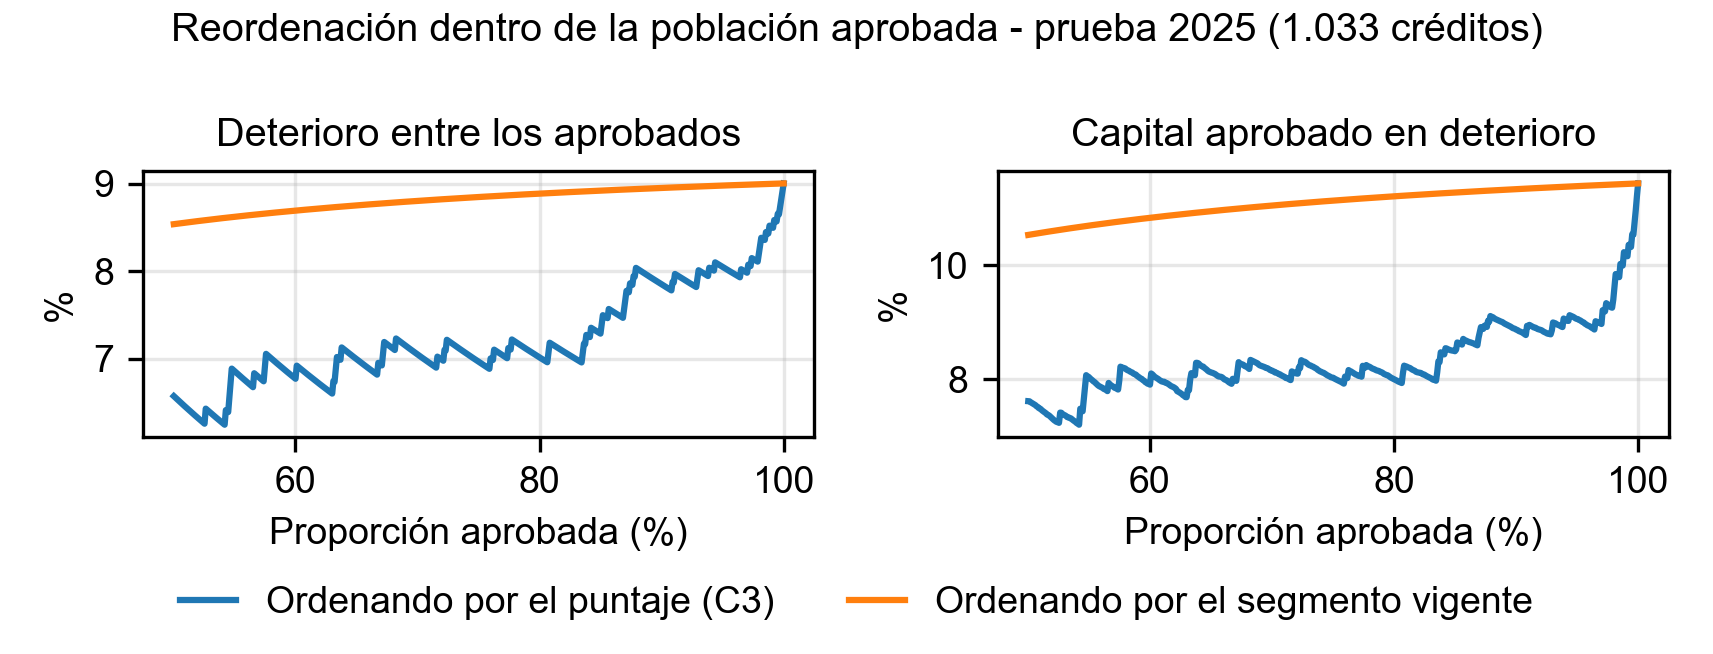

In [9]:
display(Image(str(H / "h2" / "frontera.png")))

**Lectura de H2:**
- **(a) A igual tasa de aprobación, el puntaje deja menos deterioro que el segmento en los seis puntos evaluados (70 % a 95 %),** con reducciones de 0,9 a 1,9 puntos.
  - Aprobando el 80 %, el deterioro entre los aprobados es de 7,0 % frente a 8,9 % con el segmento: −1,9 puntos [−3,0; −0,8].
  - La proporción del capital aprobado que entra en deterioro baja de 11,2 % a 8,0 %: −3,2 puntos [−5,0; −1,4].
  - La cartera completa tiene 9,0 % de deterioro y 11,4 % del capital en deterioro.
- **(b) A igual deterioro, el máximo registrado no separa los criterios y los complementarios son muy imprecisos.**
  - Con un máximo de 9 %, igual a la mora de la prueba, el puntaje aprueba el 99,9 % de la cartera y el segmento el 99,3 % (p = 0,97).
  - Con el máximo complementario de 7 %, el puntaje permite aprobar el 83,4 % y el segmento el 18,8 % (+64,7 puntos [−2,1; +83,3], p = 0,077); con el de 8 %, el 97,0 % y el 31,7 % ([0,0; +87,3], p = 0,257).
  - La fracción aprobable a deterioro fijo salta cada vez que la tasa acumulada cruza el umbral, y con 93 eventos no se estima con precisión.
- **Conclusión:** según la regla registrada, **H2 no alcanza un apoyo concluyente**. La evidencia de (a), consistente en todas las tasas, indica que reordenar con el puntaje sí reduce el deterioro y el capital en deterioro a igual aprobación: un efecto modesto, coherente con un AUC de 0,62.

### 2.1 Capa prospectiva: escenarios de prevalencia

El modelo sobreestima el nivel del riesgo en 2025 (notebook 05), así que la exposición esperada solo se puede calcular recalibrando el intercepto bajo prevalencias supuestas de 10, 13 y 20 %. **Son escenarios, no estimaciones de pérdida:**
- La exposición esperada es la suma de probabilidad × capital.
- El ingreso contratado es lo que suman las cuotas menos el capital. Puede incluir seguros y no descuenta costos, prepagos ni recuperaciones.

In [10]:
p = leer(H / "h2" / "prospectiva_prevalencias.csv")
p[p.aprobacion.isin([0.8, 0.9, 1.0])][["prevalencia_supuesta", "aprobacion", "creditos", "prob_media_aprobados",
                                       "exposicion_sobre_capital", "ingreso_sobre_exposicion"]]

,prevalencia_supuesta,aprobacion,creditos,prob_media_aprobados,exposicion_sobre_capital,ingreso_sobre_exposicion
2,0.1000,0.8000,827,0.0848,0.0854,8.6920
4,0.1000,0.9000,930,0.0898,0.0906,8.2309
6,0.1000,1.0000,1033,0.1000,0.1072,7.1065
9,0.1300,0.8000,827,0.1112,0.1121,6.6232
11,0.1300,0.9000,930,0.1176,0.1186,6.2866
13,0.1300,1.0000,1033,0.1300,0.1386,5.4949
16,0.2000,0.8000,827,0.1747,0.1759,4.2203
18,0.2000,0.9000,930,0.1836,0.1851,4.0276
20,0.2000,1.0000,1033,0.2000,0.2111,3.6088


**Lectura:** con una prevalencia supuesta de 13 %, aprobar el 80 % de menor riesgo baja la exposición esperada de 13,9 % a 11,2 % del capital aprobado, y la razón entre el ingreso contratado y esa exposición sube de 5,5 a 6,6. El orden se mantiene en los tres escenarios. Las magnitudes dependen del supuesto de prevalencia.

### 2.2 Composición de la cartera aprobada: a quién deja fuera el corte

Para cada corte, la tabla muestra cuánto deterioro y capital quedan fuera, y qué proporción de cada categoría no se aprobaría. **El sexo y el estrato no entran al modelo:** aparecen solo para auditar a quién afecta el corte.

In [11]:
display(leer(H / "h2" / "composicion_resumen.csv"))
c = leer(H / "h2" / "composicion.csv")
c[c.aprobacion == 0.80].drop(columns="aprobacion")

,aprobacion,aprobados,no_aprobados,deterioro_aprobados,deterioro_no_aprobados,eventos_no_aprobados,pct_eventos_evitados,capital_medio_aprobados,capital_medio_no_aprobados,pct_capital_no_aprobado
0,0.7000,724,309,0.0704,0.1359,42,0.4516,"10,176,146.1022","12,122,368.0032",0.3371
1,0.8000,827,206,0.0701,0.1699,35,0.3763,"10,243,026.8912","12,826,981.8058",0.2378
2,0.9000,930,103,0.0785,0.1942,20,0.2151,"10,307,386.0871","14,829,829.4175",0.1374


,atributo,categoria,creditos,pct_cartera,pct_entre_no_aprobados,tasa_no_aprobacion,deterioro_observado
32,segmento,BRONCE,866,0.8383,0.8786,0.2090,0.0947
33,segmento,ORO,37,0.0358,0.0340,0.1892,0.0000
34,segmento,PLATA,130,0.1258,0.0874,0.1385,0.0846
35,tipo_uso_moto,DOBLE_PROPOSITO,246,0.2381,0.4175,0.3496,0.1138
36,tipo_uso_moto,NAKED_SPORT,181,0.1752,0.3398,0.3867,0.0939
37,tipo_uso_moto,SCOOTER,460,0.4453,0.0291,0.0130,0.0565
38,tipo_uso_moto,URBANA_TRABAJO,146,0.1413,0.2136,0.3014,0.1507
39,independiente,formal,872,0.8441,0.7476,0.1766,0.0814
40,independiente,informal,161,0.1559,0.2524,0.3230,0.1366
41,estado_civil,CASADO,188,0.1820,0.0194,0.0213,0.0904


**Lectura** (aprobando el 80 % de menor riesgo en la prueba 2025):
- **Quedan fuera 206 créditos**, con un deterioro de 17,0 % frente a 7,0 % entre los aprobados.
  - Concentran el 37,6 % de los eventos y el 23,8 % del capital.
  - Su capital medio es mayor: 12,8 millones frente a 10,2.
- **El corte recae sobre todo en tres perfiles:**
  - **Solteros:** no se aprueba al 31,1 %, frente a 2,1 % de los casados y 6,6 % en unión libre. Son el 86,9 % de los no aprobados.
  - **Motos de doble propósito y deportivas:** 35,0 % y 38,7 % de no aprobación, frente a 1,3 % en los scooter.
  - **Independientes informales:** 32,3 %, frente a 17,7 % de los formales.
- **Grupos de auditoría:**
  - Por sexo, la no aprobación es de 17,3 % en mujeres y 21,7 % en hombres.
  - Por estrato, va de 12,4 % en el 1-2 a 24,8 % en el 5+.
- **Segmento Oro:** ninguno de sus 37 créditos se deterioró, y aun así el corte deja fuera al 18,9 %. El puntaje y el segmento ordenan de forma distinta.
- El peso del estado civil en el corte es el rasgo que más conviene vigilar en el uso del modelo.

### 2.3 Sensibilidad: C3 sin el estado civil (exploratorio)

El corte del 80 % recae sobre todo en los solteros (31,1 % sin aprobar, frente a 2,1 % de los casados). Como el estado civil es un atributo protegido en otras jurisdicciones, se ajusta **fuera del protocolo** una versión de C3 sin esa variable (edad, ciudad, independiente informal, nivel de estudio y familia de moto) con el mismo procedimiento: Optuna y validación cruzada 5×5 dentro de 2023-2024 (`src/04a_versiones_cv.py`) y una sola calificación de 2025 (`src/07b_hipotesis2_3.py --sensibilidad-estado-civil`). Se compara su AUC con el de C3 y se recalcula a quién deja fuera el corte del 80 %, por estado civil y por edad.

In [12]:
display(leer(H / "h2" / "sensibilidad_estado_civil_auc.csv"))
display(leer(H / "h2" / "sensibilidad_estado_civil_resumen.csv"))
display(leer(H / "h2" / "sensibilidad_estado_civil_composicion.csv"))

,version,variables,auc_cv,auc_cv_C3,dif_cv,cv_ic_inf,cv_ic_sup,p_cv,auc_2025,auc_2025_C3,dif_2025,ic_inf_2025,ic_sup_2025,p_2025
0,S_C3_sin_estado_civil,"edad, ciudad, independiente_informal, nivel_estudio, familia_moto",0.6245,0.6368,-0.0123,-0.0341,0.0095,0.2567,0.6395,0.6197,0.0199,-0.0108,0.0505,0.2037


,puntaje,aprobados,deterioro_aprobados,deterioro_no_aprobados
0,C3,827,0.0701,0.1699
1,sin estado civil,827,0.0726,0.1602


,atributo,categoria,creditos,C3,sin estado civil
0,edad_g,18-25,171,0.2281,0.1637
1,edad_g,26-30,175,0.1657,0.1429
2,edad_g,31-35,203,0.1626,0.1773
3,edad_g,36-40,167,0.1437,0.1377
4,edad_g,41-50,169,0.1834,0.2367
5,edad_g,51+,148,0.3378,0.3649
6,estado_civil,CASADO,188,0.0213,0.1809
7,estado_civil,FALTANTE,2,0.5000,0.5000
8,estado_civil,SEPARADO,6,0.3333,0.1667
9,estado_civil,SOLTERO,576,0.3108,0.2188


**Lectura de la sensibilidad:**
- **El AUC no se distingue del de C3:** 0,625 frente a 0,637 en validación cruzada (−0,012 [−0,034; +0,010], p = 0,257) y 0,640 frente a 0,620 en 2025 (+0,020 [−0,011; +0,050], p = 0,204).
- **El corte deja de concentrarse en los solteros:** aprobando el 80 %, quedaría fuera el 21,9 % de los solteros y el 18,1 % de los casados, frente a 31,1 % y 2,1 % con C3; en la unión libre, 16,3 % frente a 6,6 %.
- **El deterioro entre los aprobados sube un poco:** 7,3 % frente a 7,0 % con C3.
- **La edad sigue pesando:** quedaría fuera el 36,5 % de los mayores de 51 años, frente a 33,8 % con C3.
- Es una sensibilidad exploratoria: C3 sigue siendo la versión elegida con la regla registrada, y si conviene usar el estado civil en la decisión es una valoración que corresponde a la entidad.

## 3. Tercera hipótesis: equidad por sexo y estrato

> *Las métricas de error, de selección y de calibración del modelo de mejor desempeño predictivo difieren entre los subgrupos definidos por el sexo y el estrato. La existencia de diferencias estadísticas no constituye por sí sola evidencia de sesgo indebido.*

**Reglas fijadas antes de ejecutar los análisis:**
- **Criterio priorizado:** igualdad de oportunidad (Hardt, Price y Srebro, 2016), con "buen pagador" como clase favorable. Equivale a igualar la **tasa de falsos positivos**: quedar marcado sin llegar a deteriorarse.
- **Punto de operación:** marcar el 20 % de mayor riesgo.
- **Familia confirmatoria (Holm):** brechas de falsos positivos y de AUC dentro del grupo, por sexo (mujeres frente a hombres) y por estrato (frente al estrato 4, el más numeroso).
- **Interpretación:** solo subgrupos con 30 créditos y 10 eventos como mínimo. Las demás métricas son descriptivas.

In [13]:
g = leer(H / "h3" / "grupos_2025.csv")
display(g[g.punto == 0.20])
b = leer(H / "h3" / "brechas_2025.csv")
print("Familia confirmatoria (20 %, Holm):")
display(b[b.en_familia][["atributo", "grupo", "referencia", "metrica", "brecha", "ic_inf", "ic_sup", "p", "p_holm"]])
print("Brechas descriptivas al 20 %:")
display(b[(b.punto == 0.20) & ~b.confirmatoria][["atributo", "grupo", "referencia", "metrica", "brecha", "ic_inf", "ic_sup", "p"]])

,atributo,grupo,punto,n,eventos,tasa_observada,prob_media,observado_sobre_esperado,pct_marcados,tpr,fpr,auc,interpretable
2,sexo,F,0.2000,415,21,0.0506,0.2073,0.2441,0.1735,0.3810,0.1624,0.6166,True
3,sexo,M,0.2000,618,72,0.1165,0.2152,0.5413,0.2184,0.3750,0.1978,0.6129,True
10,estrato_g,1-2,0.2000,121,11,0.0909,0.1947,0.4670,0.1240,0.1818,0.1182,0.6074,True
11,estrato_g,3,0.2000,337,23,0.0682,0.2100,0.3249,0.1840,0.3043,0.1752,0.5532,True
12,estrato_g,4,0.2000,430,42,0.0977,0.2177,0.4487,0.2163,0.4524,0.1907,0.6580,True
13,estrato_g,5+,0.2000,145,17,0.1172,0.2146,0.5464,0.2552,0.4118,0.2344,0.6390,True


Familia confirmatoria (20 %, Holm):


,atributo,grupo,referencia,metrica,brecha,ic_inf,ic_sup,p,p_holm
20,sexo,F,M,fpr,-0.0354,-0.0820,0.0164,0.2080,1.0000
21,sexo,F,M,auc,0.0037,-0.1544,0.1557,0.9480,1.0000
25,estrato_g,1-2,4,fpr,-0.0725,-0.1391,0.0067,0.0700,0.5600
26,estrato_g,1-2,4,auc,-0.0505,-0.2456,0.1290,0.5830,1.0000
30,estrato_g,3,4,fpr,-0.0156,-0.0780,0.0471,0.6510,1.0000
31,estrato_g,3,4,auc,-0.1048,-0.2683,0.0662,0.2110,1.0000
35,estrato_g,5+,4,fpr,0.0437,-0.0460,0.1240,0.3510,1.0000
36,estrato_g,5+,4,auc,-0.0189,-0.2058,0.1565,0.8170,1.0000


Brechas descriptivas al 20 %:


,atributo,grupo,referencia,metrica,brecha,ic_inf,ic_sup,p
22,sexo,F,M,pct_marcados,-0.0450,-0.0917,0.0074,0.0770
23,sexo,F,M,tpr,0.0060,-0.2386,0.2295,0.9420
24,sexo,F,M,observado_sobre_esperado,-0.2972,-0.4427,-0.1382,0.0000
27,estrato_g,1-2,4,pct_marcados,-0.0923,-0.1603,-0.0195,0.0150
28,estrato_g,1-2,4,tpr,-0.2706,-0.5435,0.0097,0.0590
29,estrato_g,1-2,4,observado_sobre_esperado,0.0183,-0.2561,0.3253,0.8940
32,estrato_g,3,4,pct_marcados,-0.0323,-0.0906,0.0278,0.3160
33,estrato_g,3,4,tpr,-0.1480,-0.3727,0.1165,0.2800
34,estrato_g,3,4,observado_sobre_esperado,-0.1238,-0.3033,0.0464,0.1600
37,estrato_g,5+,4,pct_marcados,0.0389,-0.0465,0.1199,0.3890


In [14]:
# Brechas de falsos positivos en los otros dos cortes de la frontera (descriptivas)
b[(b.metrica == "fpr") & b.punto.isin([0.1, 0.3])][["punto", "atributo", "grupo", "referencia", "brecha", "ic_inf", "ic_sup", "p"]]

,punto,atributo,grupo,referencia,brecha,ic_inf,ic_sup,p
0,0.1000,sexo,F,M,-0.0184,-0.0617,0.0154,0.2160
5,0.1000,estrato_g,1-2,4,-0.0252,-0.0779,0.0383,0.4450
10,0.1000,estrato_g,3,4,-0.0247,-0.0674,0.0152,0.2100
15,0.1000,estrato_g,5+,4,0.0192,-0.0581,0.0922,0.6890
40,0.3000,sexo,F,M,-0.0364,-0.0955,0.0219,0.2370
45,0.3000,estrato_g,1-2,4,-0.0938,-0.1795,-0.0032,0.0400
50,0.3000,estrato_g,3,4,0.0055,-0.0600,0.0773,0.7310
55,0.3000,estrato_g,5+,4,0.0031,-0.0925,0.0971,0.9560


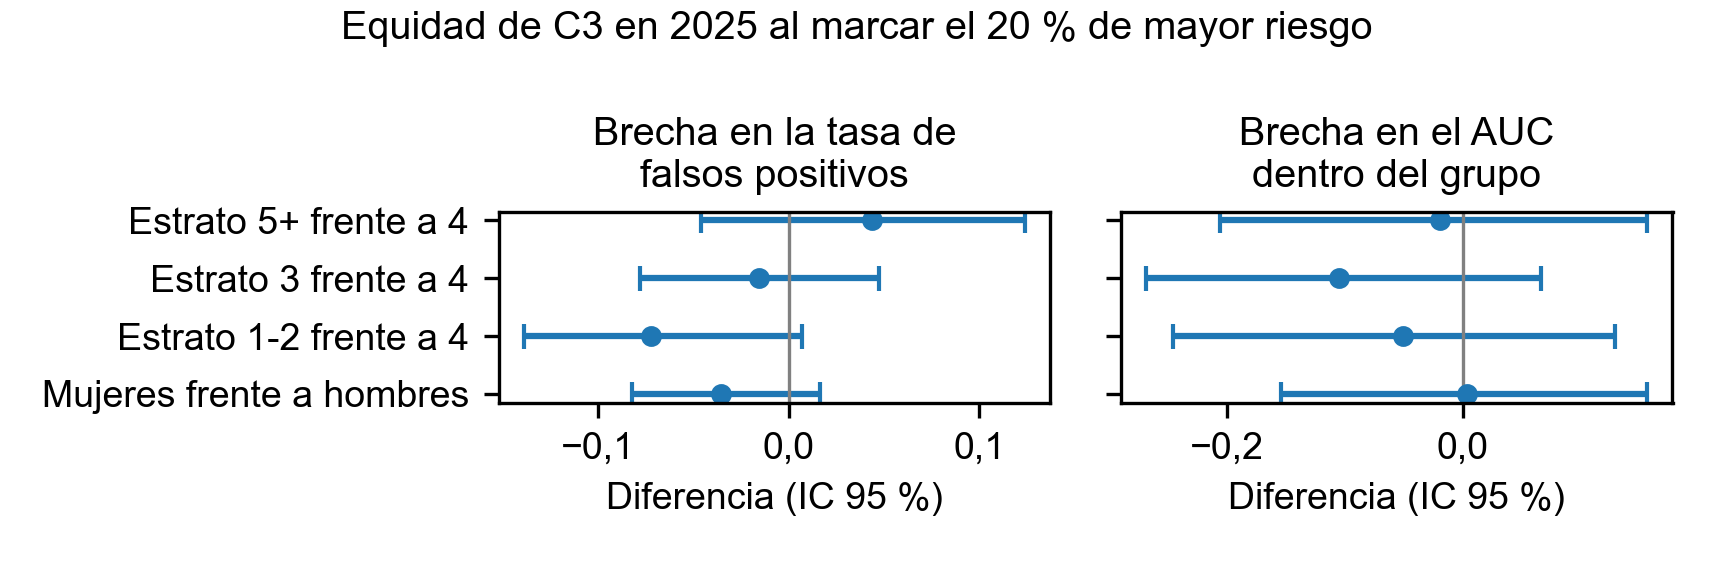

In [15]:
display(Image(str(H / "h3" / "brechas.png")))

### 3.1 Complemento: predicciones fuera de pliegue 2023-2024 (descriptivo)

In [16]:
leer(H / "h3" / "grupos_oof_2023_2024.csv")

,atributo,grupo,punto,n,eventos,tasa_observada,prob_media,observado_sobre_esperado,pct_marcados,tpr,fpr,auc,interpretable
0,sexo,F,0.2000,655,126,0.1924,0.2213,0.8692,0.1588,0.2540,0.1361,0.6538,True
1,sexo,M,0.2000,1220,309,0.2533,0.2373,1.0671,0.2221,0.3528,0.1778,0.6331,True
2,estrato_g,1-2,0.2000,155,27,0.1742,0.2094,0.8320,0.1097,0.1111,0.1094,0.7031,True
3,estrato_g,3,0.2000,581,149,0.2565,0.2367,1.0835,0.2100,0.3557,0.1597,0.6425,True
4,estrato_g,4,0.2000,829,182,0.2195,0.2339,0.9386,0.2195,0.3297,0.1886,0.6373,True
5,estrato_g,5+,0.2000,310,77,0.2484,0.2279,1.0899,0.1742,0.3247,0.1245,0.6219,True


### 3.2 Prueba de proxy: ¿las variables o el puntaje reconstruyen el sexo o el estrato?

In [17]:
leer(H / "h3" / "prueba_proxy.csv")

,atributo,n,prevalencia,auc_desde_variables_C3_cv,auc_desde_puntaje_2025
0,sexo = M,2908,0.6320,0.6059,0.5357
1,estrato 5+,2908,0.1565,0.6953,0.5111
2,estrato 1-2,2908,0.0949,0.8258,0.4146


### 3.3 ¿El estrato se asocia con el deterioro una vez se tiene en cuenta el producto y el crédito?

In [18]:
display(leer(H / "h3" / "estrato_condicionado.csv"))
t = pd.read_csv(H / "h3" / "estrato_tasas_por_anio.csv", encoding="utf-8-sig", header=[0, 1], index_col=0)
display(t.set_axis([f"{'créditos' if a == 'size' else 'mora 30+'} {b}" for a, b in t.columns], axis=1).rename_axis("estrato"))

,modelo,termino,odds_ratio,ic_inf,ic_sup,p,n
0,estrato + año,1-2 frente a 4,0.8664,0.5918,1.2684,0.4609,2908
1,estrato + año,3 frente a 4,1.1277,0.8991,1.4144,0.2983,2908
2,estrato + año,5+ frente a 4,1.2555,0.9516,1.6564,0.1076,2908
3,+ producto y condiciones,1-2 frente a 4,0.9968,0.6700,1.4830,0.9875,2908
4,+ producto y condiciones,3 frente a 4,1.1286,0.8890,1.4328,0.3203,2908
5,+ producto y condiciones,5+ frente a 4,1.2719,0.9483,1.7060,0.1083,2908


,créditos 2023,créditos 2024,créditos 2025,mora 30+ 2023,mora 30+ 2024,mora 30+ 2025
estrato,,,,,,
1-2,32,123,121,0.2500,0.1545,0.0909
3,161,420,337,0.4099,0.1976,0.0682
4,260,569,430,0.3231,0.1722,0.0977
5+,75,235,145,0.3467,0.2170,0.1172


**Lectura de H3:**
- **En el criterio priorizado no hay diferencias que los datos sostengan.** Ninguna de las ocho brechas de la familia confirmatoria resiste la corrección de Holm; el p de Holm más bajo es 0,56.
  - **Sexo:** la brecha de falsos positivos es de −3,5 puntos [−8,2; +1,6] y la de AUC de +0,004 [−0,154; +0,156].
  - **Estrato:** la brecha que más se acerca es la de falsos positivos del estrato 1-2 frente al 4, de −7,3 puntos [−13,9; +0,7] (p sin corregir de 0,070).
  - **Otros cortes:** al marcar el 10 %, ningún intervalo de las brechas de falsos positivos excluye el cero; al marcar el 30 %, el del estrato 1-2 frente al 4 sí lo hace (−9,4 puntos [−17,9; −0,3]), con menos falsos positivos para el estrato 1-2, como resultado descriptivo fuera de la familia confirmatoria.
  - **Conclusión:** H3 no encuentra apoyo en la igualdad de oportunidad ni en la discriminación dentro de los grupos.
- **Hay diferencias descriptivas en calibración y en selección**, que la hipótesis también nombra:
  - El modelo sobreestima más el riesgo de las mujeres: observado/esperado de 0,24 frente a 0,54 en los hombres, brecha de −0,30 [−0,44; −0,14]. Excluir el sexo no las protege de eso: les asigna un riesgo promedio de 20,7 %, frente a 21,5 % en los hombres, cuando su tasa observada es menor (5,1 % frente a 11,7 %).
  - Incluir el sexo tampoco lo corrige: con la versión con sexo, el observado/esperado es de 0,26 y 0,52, y la brecha de falsos positivos al marcar el 20 % se amplía de −3,5 a −10,2 puntos (notebook 05).
  - El estrato 1-2 queda marcado con menos frecuencia (12,4 % frente a 21,6 % del estrato 4; −9,2 puntos [−16,0; −1,9]), lo que, en clave de inclusión, no perjudica a los estratos bajos; su tasa de verdaderos positivos es más baja (18,2 %), aunque solo tiene 11 eventos.
  - Estas brechas están fuera de la familia confirmatoria y se reportan como descriptivas.
- **2023-2024:** las predicciones fuera de pliegue van en la misma dirección (observado/esperado de 0,87 en mujeres y 1,07 en hombres; falsos positivos de 13,6 % y 17,8 %; 10,9 % en el estrato 1-2 y 18,9 % en el 4).
- **Proxy:**
  - Las seis variables de C3 permiten reconstruir el estrato 1-2 con un AUC de 0,83, el estrato 5+ con 0,70 y el sexo con 0,61.
  - El puntaje distingue poco el sexo (0,536) y el estrato 5+ (0,511).
  - Al estrato 1-2 le asigna un riesgo algo menor: AUC de 0,415, es decir, 0,585 en sentido inverso. La información del estrato está en las variables y una parte llega al puntaje.
- **Estrato y deterioro:** la tasa más alta del estrato 5+ en 2025 (11,7 %, frente a 9,8 % del estrato 4) no se sostiene en la población completa. Frente al estrato 4, la razón de odds es 1,26 [0,95; 1,66] controlando por el año, y 1,27 [0,95; 1,71] agregando producto y condiciones del crédito.
- Una diferencia estadística no es por sí sola un sesgo indebido. El trabajo evalúa y no corrige; la calibración por grupo se incluye en el plan de monitoreo.

## 4. Calibración en el conjunto

Para cada periodo se reportan la razón observado/esperado (O/E) y el intercepto estimado con la pendiente fija en 1 (offset del logit), según Van Calster et al. (2016, 2019). Un intercepto negativo indica que el modelo sobreestima el nivel del riesgo.

In [19]:
leer(H / "calibracion" / "calibracion_en_el_conjunto.csv")

,periodo,fuente,n,tasa_observada,prob_media,observado_sobre_esperado,intercepto_offset,ic_inf,ic_sup
0,2023,CV (fuera de pliegue),528,0.3485,0.2387,1.4602,0.5504,0.3686,0.7323
1,2024,CV (fuera de pliegue),1347,0.1863,0.2290,0.8136,-0.2690,-0.4084,-0.1297
2,2025,prueba,1033,0.0900,0.2121,0.4245,-1.0253,-1.2403,-0.8103
3,2025-T2,prueba sin recalibrar,534,0.0768,0.2101,0.3654,-1.1871,-1.5080,-0.8662
4,2025-T2,prueba recalibrada con 2025-T1,534,0.0768,0.1015,0.7561,-0.3118,-0.6327,0.0091
5,2025,prueba · sexo F,415,0.0506,0.2073,0.2441,-1.6215,-2.0629,-1.1801
6,2025,prueba · sexo M,618,0.1165,0.2152,0.5413,-0.7523,-1.0009,-0.5038
7,2025,prueba · estrato_g 1-2,121,0.0909,0.1947,0.4670,-0.8976,-1.5214,-0.2738
8,2025,prueba · estrato_g 3,337,0.0682,0.2100,0.3249,-1.3143,-1.7405,-0.8882
9,2025,prueba · estrato_g 4,430,0.0977,0.2177,0.4487,-0.9706,-1.2924,-0.6488


**Lectura:**
- El nivel del modelo sigue la caída de la mora entre cosechas, pero con retraso:
  - En 2023 lo subestima (O/E de 1,46).
  - En 2024 lo sobreestima (O/E de 0,81, intercepto de −0,27 [−0,41; −0,13]).
  - En 2025 lo sobreestima con más fuerza: O/E de 0,42 e intercepto de −1,03 [−1,24; −0,81].
- Recalibrando el intercepto con 2025-T1, en 2025-T2 el O/E pasa de 0,37 a 0,76 y el intercepto queda en −0,31 [−0,63; +0,01], en el límite de la significancia; la sobreestimación se reduce, pero no desaparece.
- La pendiente, que mide el orden, es mayor que 1 en todos los años (notebook 05). Lo que se pierde es el nivel, y se corrige recalibrando con la cosecha madura más reciente.

## 5. Síntesis

| Hipótesis | Contraste registrado | Resultado |
|---|---|---|
| H1 (referencia) | E3 − E1 en 2025, AUC y Brier, Holm | AUC +0,013 [−0,014; +0,040] (Holm 0,68) y Brier −0,0003 [−0,0018; +0,0012] (Holm 0,70): **no se sostiene**, tampoco frente a un E1 solo con las condiciones del crédito (sensibilidad: +0,008 [−0,022; +0,038] en AUC). El bloque financiero concentra la capacidad predictiva |
| H2 | Fracción aprobable con deterioro ≤ 9 %, puntaje frente a segmento | 99,9 % frente a 99,3 %: **no concluyente** (el máximo coincide con la mora de la prueba; con 7 %, [−2,1; +83,3]); a igual aprobación, el deterioro baja en todos los puntos (80 %: −1,9 puntos [−3,0; −0,8]) |
| H3 | Brechas de falsos positivos y de AUC por sexo y estrato, Holm | **ninguna resiste Holm**; diferencias descriptivas en calibración por sexo (O/E 0,24 frente a 0,54) y en selección por estrato |